<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-05-CNN/DL_Tutorial_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [3]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 170M/170M [45:36<00:00, 62.3kB/s]


In [4]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [5]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


In [6]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", class_names[label])

Image shape: torch.Size([3, 32, 32])
Label: 6
Class: frog


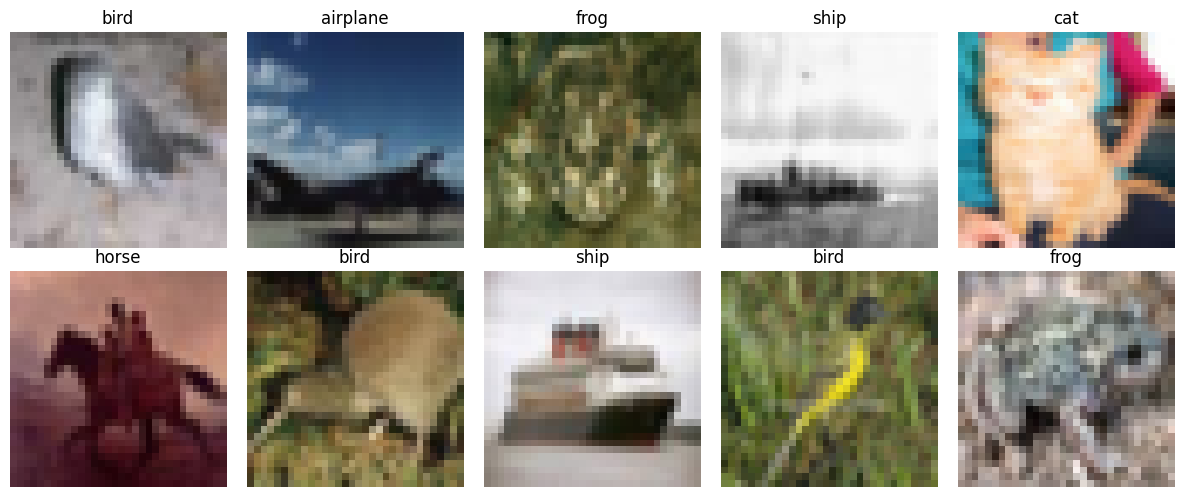

In [7]:
data_iter = iter(train_loader)

images, labels = next(data_iter)

plt.figure(figsize=(12, 5))

for i in range(10):

    image = images[i].permute(1, 2, 0)

    plt.subplot(2, 5, i + 1)

    plt.imshow(image)

    plt.title(class_names[labels[i].item()])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
class CNN(nn.Module):

    def __init__(self):

        super(CNN, self).__init__()

        # First convolution layer
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3
        )

        # Second convolution layer
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3
        )

        # Third convolution layer
        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=64,
            kernel_size=3
        )

        # Max pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Activation
        self.relu = nn.ReLU()

        # Fully connected layers
        self.fc1 = nn.Linear(
            64 * 4 * 4,
            64
        )

        self.fc2 = nn.Linear(
            64,
            10
        )


    def forward(self, x):

        # Conv 1
        x = self.relu(
            self.conv1(x)
        )

        x = self.pool(x)


        # Conv 2
        x = self.relu(
            self.conv2(x)
        )

        x = self.pool(x)


        # Conv 3
        x = self.relu(
            self.conv3(x)
        )


        # Flatten
        x = torch.flatten(
            x,
            start_dim=1
        )


        # Fully connected
        x = self.relu(
            self.fc1(x)
        )


        # Output
        x = self.fc2(x)

        return x

In [12]:
model = CNN().to(device)

print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=1024, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)


In [13]:
nn.Linear(64 * 4 * 4, 64)

Linear(in_features=1024, out_features=64, bias=True)

In [14]:
nn.CrossEntropyLoss()

CrossEntropyLoss()

In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [16]:
train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []

In [17]:
epochs = 10

for epoch in range(epochs):

    # =========================
    # TRAINING
    # =========================

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0


    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)


        # Clear previous gradients
        optimizer.zero_grad()


        # Forward propagation
        outputs = model(images)


        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )


        # Backpropagation
        loss.backward()


        # Update weights
        optimizer.step()


        running_loss += (
            loss.item() * images.size(0)
        )


        # Predictions
        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    train_loss = (
        running_loss /
        len(train_loader.dataset)
    )

    train_accuracy = (
        100 * correct / total
    )


    # =========================
    # VALIDATION / TESTING
    # =========================

    model.eval()

    running_test_loss = 0.0

    correct = 0
    total = 0


    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)


            outputs = model(images)


            loss = criterion(
                outputs,
                labels
            )


            running_test_loss += (
                loss.item() * images.size(0)
            )


            _, predicted = torch.max(
                outputs,
                1
            )


            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()


    test_loss = (
        running_test_loss /
        len(test_loader.dataset)
    )

    test_accuracy = (
        100 * correct / total
    )


    # Save values
    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)


    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {test_loss:.4f} "
        f"Val Acc: {test_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.7104 Train Acc: 36.74% Val Loss: 1.4966 Val Acc: 45.59%
Epoch [2/10] Train Loss: 1.3695 Train Acc: 50.43% Val Loss: 1.2894 Val Acc: 53.04%
Epoch [3/10] Train Loss: 1.2374 Train Acc: 55.76% Val Loss: 1.2208 Val Acc: 56.09%
Epoch [4/10] Train Loss: 1.1365 Train Acc: 59.72% Val Loss: 1.0961 Val Acc: 61.34%
Epoch [5/10] Train Loss: 1.0683 Train Acc: 62.13% Val Loss: 1.0793 Val Acc: 62.01%
Epoch [6/10] Train Loss: 1.0011 Train Acc: 64.72% Val Loss: 1.0343 Val Acc: 63.90%
Epoch [7/10] Train Loss: 0.9518 Train Acc: 66.53% Val Loss: 0.9906 Val Acc: 65.12%
Epoch [8/10] Train Loss: 0.9071 Train Acc: 68.01% Val Loss: 1.0047 Val Acc: 64.82%
Epoch [9/10] Train Loss: 0.8630 Train Acc: 69.65% Val Loss: 0.9402 Val Acc: 67.32%
Epoch [10/10] Train Loss: 0.8289 Train Acc: 70.90% Val Loss: 0.9194 Val Acc: 67.84%


In [18]:
model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        test_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


test_loss = (
    test_loss /
    len(test_loader.dataset)
)

test_accuracy = (
    100 * correct / total
)


print(
    "Final Test Loss:",
    round(test_loss, 4)
)

print(
    "Final Test Accuracy:",
    round(test_accuracy, 2),
    "%"
)

Final Test Loss: 0.9194
Final Test Accuracy: 67.84 %


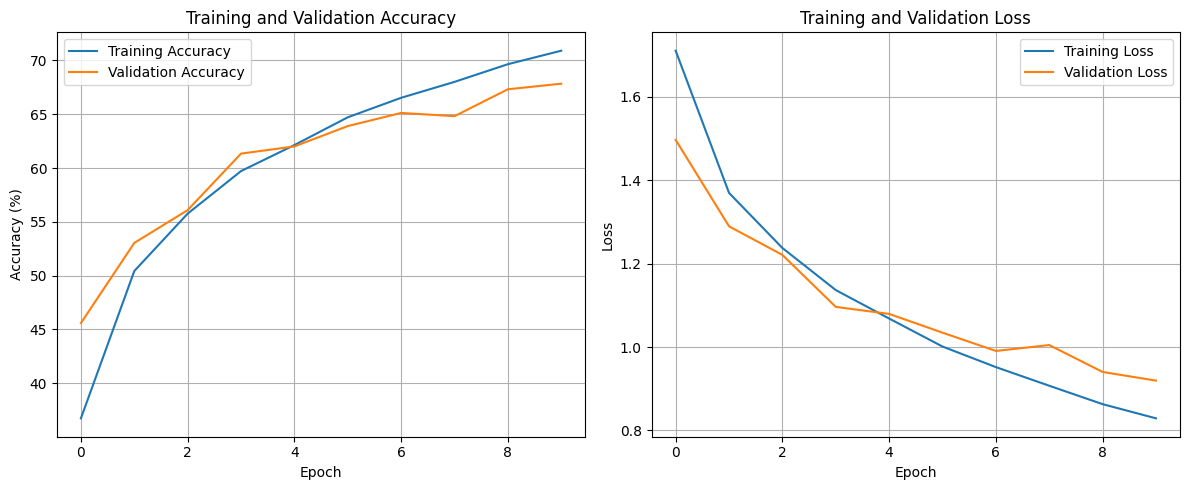

In [19]:
plt.figure(figsize=(12, 5))


# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    test_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    test_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid()


plt.tight_layout()
plt.show()

In [20]:
model.eval()

images, labels = next(
    iter(test_loader)
)

images = images.to(device)

with torch.no_grad():

    outputs = model(images)

    _, predictions = torch.max(
        outputs,
        1
    )

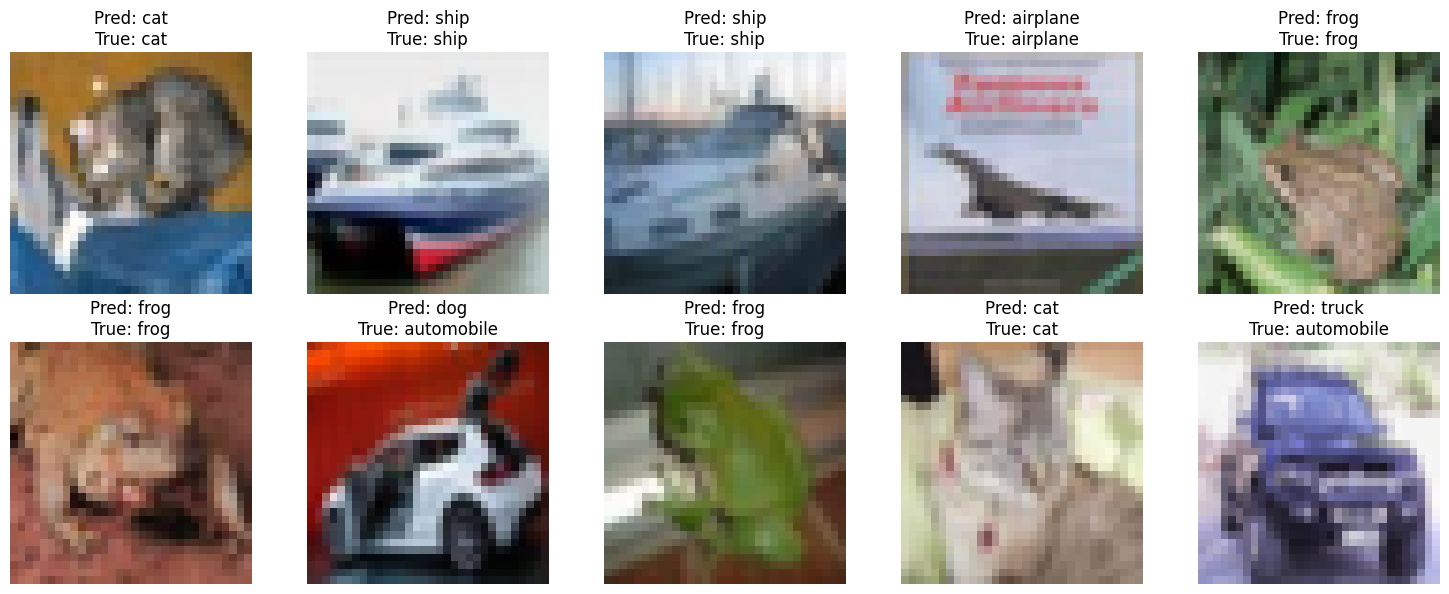

In [21]:
images = images.cpu()

predictions = predictions.cpu()

plt.figure(figsize=(15, 6))

for i in range(10):

    image = images[i].permute(
        1,
        2,
        0
    )

    plt.subplot(
        2,
        5,
        i + 1
    )

    plt.imshow(image)

    predicted_class = class_names[
        predictions[i].item()
    ]

    true_class = class_names[
        labels[i].item()
    ]


    plt.title(
        f"Pred: {predicted_class}\n"
        f"True: {true_class}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

## Baseline CNN Results and Observation

The baseline CNN was trained for 10 epochs on the CIFAR-10 dataset using the Adam optimizer and cross-entropy loss.

The final results were:

- Training Accuracy: **70.90%**
- Test Accuracy: **67.84%**
- Training Loss: **0.8289**
- Test Loss: **0.9194**

Both training and test accuracy increased during training, while the losses generally decreased. This indicates that the model successfully learned features from the CIFAR-10 images.

The final accuracy gap was approximately **3.06 percentage points**, indicating relatively limited overfitting at this stage. However, the model still has room for improvement in classification accuracy.

This baseline will be used as the reference for comparing the modified CNN architectures.

# Task 1A — Effect of Kernel Size

In [22]:
class CNN_5x5(nn.Module):

    def __init__(self):
        super(CNN_5x5, self).__init__()

        # Convolution layer 1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=5
        )

        # Convolution layer 2
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=5
        )

        # Convolution layer 3
        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=64,
            kernel_size=3
        )

        # Max pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.relu = nn.ReLU()

        # Fully connected layers
        self.fc1 = nn.Linear(
            64 * 3 * 3,
            64
        )

        self.fc2 = nn.Linear(
            64,
            10
        )


    def forward(self, x):

        x = self.relu(self.conv1(x))
        x = self.pool(x)

        x = self.relu(self.conv2(x))
        x = self.pool(x)

        x = self.relu(self.conv3(x))

        x = torch.flatten(x, start_dim=1)

        x = self.relu(self.fc1(x))

        x = self.fc2(x)

        return x

In [23]:
model_5x5 = CNN_5x5().to(device)

print(model_5x5)

CNN_5x5(
  (conv1): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=576, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)


In [24]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_5x5.parameters(),
    lr=0.001
)

train_losses_5 = []
test_losses_5 = []

train_accuracies_5 = []
test_accuracies_5 = []

epochs = 10

for epoch in range(epochs):

    model_5x5.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_5x5(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    train_loss = (
        running_loss /
        len(train_loader.dataset)
    )

    train_accuracy = (
        100 * correct / total
    )


    model_5x5.eval()

    running_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_5x5(images)

            loss = criterion(
                outputs,
                labels
            )

            running_test_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()


    test_loss = (
        running_test_loss /
        len(test_loader.dataset)
    )

    test_accuracy = (
        100 * correct / total
    )


    train_losses_5.append(train_loss)
    test_losses_5.append(test_loss)

    train_accuracies_5.append(train_accuracy)
    test_accuracies_5.append(test_accuracy)


    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {test_loss:.4f} "
        f"Val Acc: {test_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.7199 Train Acc: 35.95% Val Loss: 1.5774 Val Acc: 42.92%
Epoch [2/10] Train Loss: 1.3863 Train Acc: 49.51% Val Loss: 1.3473 Val Acc: 50.20%
Epoch [3/10] Train Loss: 1.2386 Train Acc: 55.25% Val Loss: 1.2613 Val Acc: 54.63%
Epoch [4/10] Train Loss: 1.1395 Train Acc: 59.14% Val Loss: 1.1365 Val Acc: 59.19%
Epoch [5/10] Train Loss: 1.0632 Train Acc: 61.90% Val Loss: 1.0664 Val Acc: 62.11%
Epoch [6/10] Train Loss: 1.0025 Train Acc: 64.32% Val Loss: 1.0226 Val Acc: 63.59%
Epoch [7/10] Train Loss: 0.9544 Train Acc: 66.14% Val Loss: 1.0055 Val Acc: 64.30%
Epoch [8/10] Train Loss: 0.9092 Train Acc: 67.81% Val Loss: 0.9468 Val Acc: 66.55%
Epoch [9/10] Train Loss: 0.8675 Train Acc: 69.19% Val Loss: 0.9652 Val Acc: 66.24%
Epoch [10/10] Train Loss: 0.8348 Train Acc: 70.49% Val Loss: 0.9231 Val Acc: 67.59%


In [25]:
test_accuracies
test_losses

[1.4965728786468506,
 1.2893604465484618,
 1.220804487991333,
 1.0961371534347535,
 1.0793439262390137,
 1.0343415409088135,
 0.9905598133087158,
 1.0046590423583985,
 0.9401531387329102,
 0.9194150211334229]

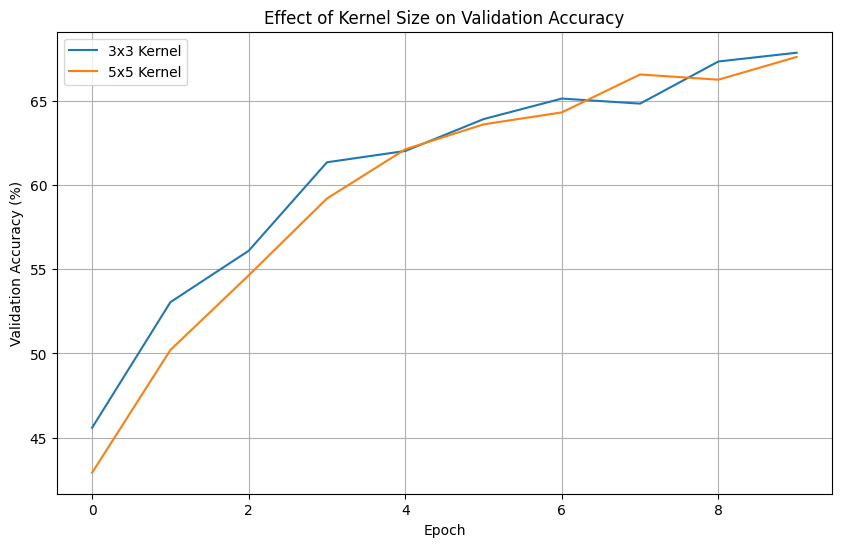

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(
    test_accuracies,
    label="3x3 Kernel"
)

plt.plot(
    test_accuracies_5,
    label="5x5 Kernel"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Effect of Kernel Size on Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

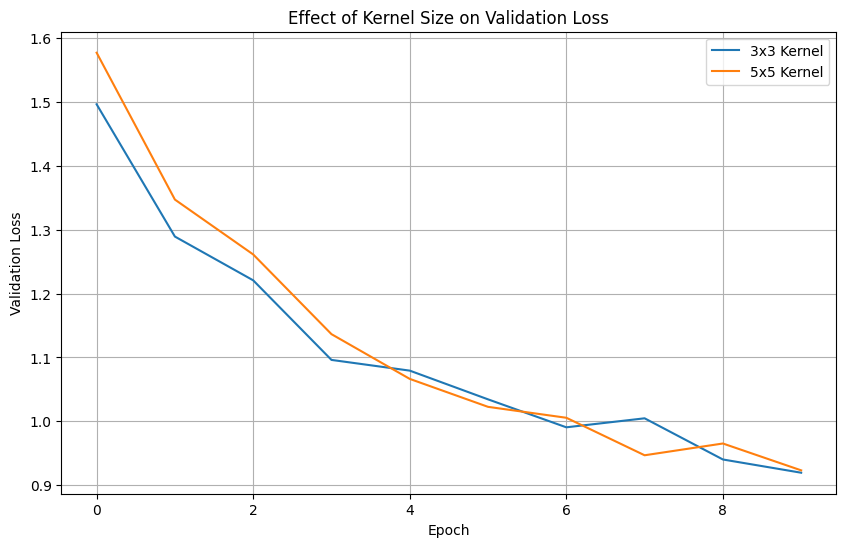

In [27]:
plt.figure(figsize=(10, 6))

plt.plot(
    test_losses,
    label="3x3 Kernel"
)

plt.plot(
    test_losses_5,
    label="5x5 Kernel"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Effect of Kernel Size on Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [28]:
print("3x3 Kernel Final Accuracy:",
      round(test_accuracies[-1], 2), "%")

print("5x5 Kernel Final Accuracy:",
      round(test_accuracies_5[-1], 2), "%")

3x3 Kernel Final Accuracy: 67.84 %
5x5 Kernel Final Accuracy: 67.59 %


## Task 1A: Effect of Kernel Size

The original CNN using 3×3 kernels was compared with a modified architecture using 5×5 kernels in the first two convolutional layers.

The original model achieved **67.84% test accuracy** with a loss of **0.9194**, while the modified 5×5 model achieved **67.59% test accuracy** with a loss of **0.9231**.

Both models performed similarly, although the original 3×3 architecture achieved slightly better accuracy and lower loss.

One possible explanation is that larger kernels reduce spatial dimensions more quickly when padding is not used. This may reduce the spatial detail available for classifying small CIFAR-10 images.

**Conclusion:** Increasing kernel size did not improve model performance in this experiment. The 3×3 baseline performed slightly better.

# Task 1B — Effect of Number of Filters and Convolution Layers

In [29]:
class CNN_Deeper(nn.Module):

    def __init__(self):
        super(CNN_Deeper, self).__init__()

        # Convolution layers
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.conv4 = nn.Conv2d(
            in_channels=128,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        # Pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Activation
        self.relu = nn.ReLU()

        # Fully connected layers
        self.fc1 = nn.Linear(
            128 * 4 * 4,
            128
        )

        self.fc2 = nn.Linear(
            128,
            10
        )


    def forward(self, x):

        # 3 x 32 x 32
        x = self.relu(self.conv1(x))

        # 32 x 32 x 32
        x = self.relu(self.conv2(x))

        # 64 x 32 x 32
        x = self.pool(x)

        # 64 x 16 x 16
        x = self.relu(self.conv3(x))

        # 128 x 16 x 16
        x = self.relu(self.conv4(x))

        # 128 x 16 x 16
        x = self.pool(x)

        # 128 x 8 x 8
        x = self.pool(x)

        # 128 x 4 x 4

        x = torch.flatten(x, start_dim=1)

        # 2048 values
        x = self.relu(self.fc1(x))

        # 128 values
        x = self.fc2(x)

        # 10 output values
        return x

In [30]:
padding=1

In [31]:
model_deeper = CNN_Deeper().to(device)

print(model_deeper)

CNN_Deeper(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [32]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_deeper.parameters(),
    lr=0.001
)

train_losses_deep = []
test_losses_deep = []

train_accuracies_deep = []
test_accuracies_deep = []

epochs = 10

for epoch in range(epochs):

    model_deeper.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_deeper(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    train_loss = (
        running_loss /
        len(train_loader.dataset)
    )

    train_accuracy = (
        100 * correct / total
    )


    model_deeper.eval()

    running_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_deeper(images)

            loss = criterion(
                outputs,
                labels
            )

            running_test_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()


    test_loss = (
        running_test_loss /
        len(test_loader.dataset)
    )

    test_accuracy = (
        100 * correct / total
    )


    train_losses_deep.append(train_loss)
    test_losses_deep.append(test_loss)

    train_accuracies_deep.append(train_accuracy)
    test_accuracies_deep.append(test_accuracy)


    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {test_loss:.4f} "
        f"Val Acc: {test_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.5402 Train Acc: 43.37% Val Loss: 1.2011 Val Acc: 56.88%
Epoch [2/10] Train Loss: 1.0449 Train Acc: 62.86% Val Loss: 0.9744 Val Acc: 65.12%
Epoch [3/10] Train Loss: 0.8550 Train Acc: 69.87% Val Loss: 0.8221 Val Acc: 71.10%
Epoch [4/10] Train Loss: 0.7309 Train Acc: 74.27% Val Loss: 0.7855 Val Acc: 72.83%
Epoch [5/10] Train Loss: 0.6418 Train Acc: 77.42% Val Loss: 0.7505 Val Acc: 73.98%
Epoch [6/10] Train Loss: 0.5637 Train Acc: 80.28% Val Loss: 0.7978 Val Acc: 73.87%
Epoch [7/10] Train Loss: 0.4997 Train Acc: 82.50% Val Loss: 0.7768 Val Acc: 73.76%
Epoch [8/10] Train Loss: 0.4392 Train Acc: 84.43% Val Loss: 0.7529 Val Acc: 75.24%
Epoch [9/10] Train Loss: 0.3873 Train Acc: 86.37% Val Loss: 0.7571 Val Acc: 75.86%
Epoch [10/10] Train Loss: 0.3337 Train Acc: 88.16% Val Loss: 0.7691 Val Acc: 76.30%


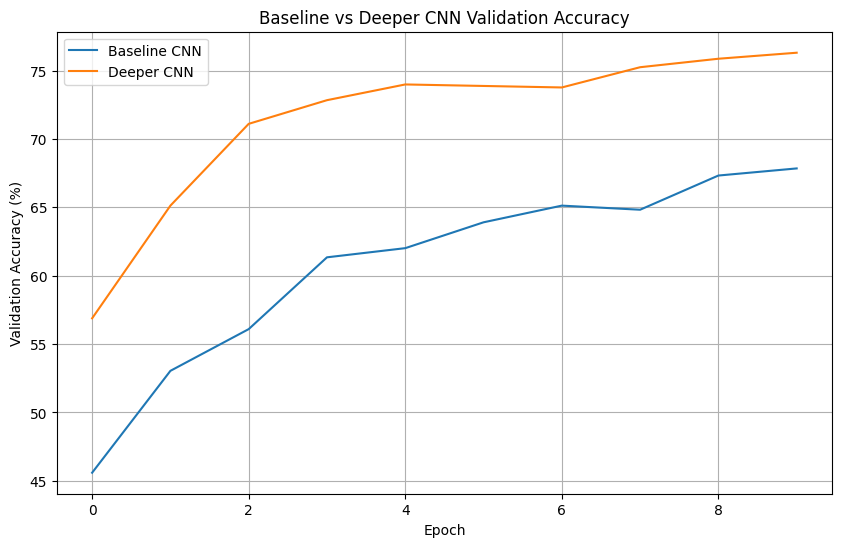

In [33]:
plt.figure(figsize=(10, 6))

plt.plot(
    test_accuracies,
    label="Baseline CNN"
)

plt.plot(
    test_accuracies_deep,
    label="Deeper CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Baseline vs Deeper CNN Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

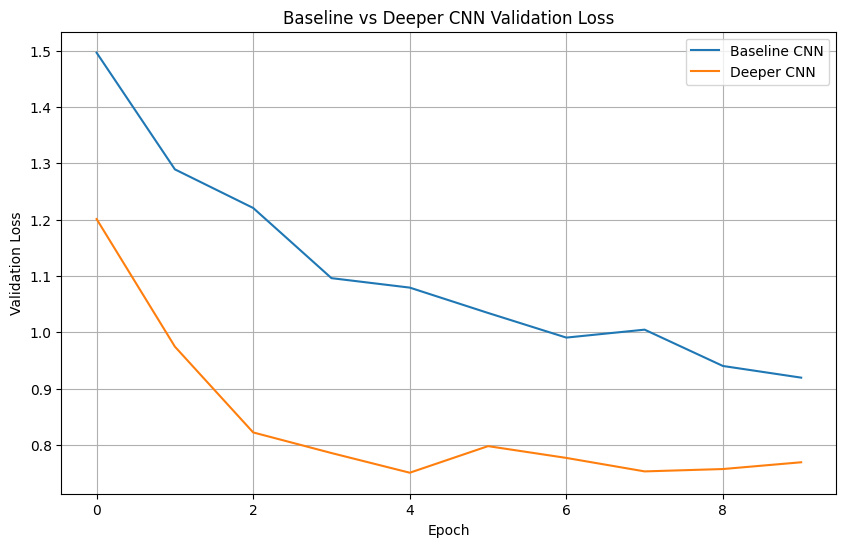

In [34]:
plt.figure(figsize=(10, 6))

plt.plot(
    test_losses,
    label="Baseline CNN"
)

plt.plot(
    test_losses_deep,
    label="Deeper CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Baseline vs Deeper CNN Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [35]:
print(
    "Baseline Final Accuracy:",
    round(test_accuracies[-1], 2),
    "%"
)

print(
    "Deeper CNN Final Accuracy:",
    round(test_accuracies_deep[-1], 2),
    "%"
)

Baseline Final Accuracy: 67.84 %
Deeper CNN Final Accuracy: 76.3 %


## Task 1B: Effect of Convolution Layers and Filters

The original CNN was modified by adding another convolutional layer and increasing the number of filters. The modified network used four convolutional layers with 32, 64, 128, and 128 filters.

The baseline CNN achieved **67.84% test accuracy** and **0.9194 test loss**.

The deeper CNN achieved **76.30% test accuracy** and **0.7691 test loss**.

Therefore, the deeper CNN improved classification accuracy by **8.46 percentage points**.

The additional convolutional layers and filters increased the model's capacity to extract and combine image features.

However, the final training accuracy reached **88.16%**, while test accuracy was **76.30%**, indicating a noticeable generalization gap.

**Conclusion:** The deeper CNN achieved significantly better classification accuracy than the baseline, but its greater capacity also increased the tendency to overfit.

# Task 1C — Effect of Fully Connected Layers and Neurons

In [36]:
class CNN_MoreFC(nn.Module):

    def __init__(self):
        super(CNN_MoreFC, self).__init__()

        # Convolution layers
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.conv4 = nn.Conv2d(
            in_channels=128,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.relu = nn.ReLU()

        # Modified fully connected layers
        self.fc1 = nn.Linear(
            128 * 4 * 4,
            256
        )

        self.fc2 = nn.Linear(
            256,
            128
        )

        self.fc3 = nn.Linear(
            128,
            10
        )


    def forward(self, x):

        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.pool(x)

        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.pool(x)

        x = self.pool(x)

        x = torch.flatten(x, start_dim=1)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))

        x = self.fc3(x)

        return x

In [37]:
model_fc = CNN_MoreFC().to(device)

print(model_fc)

CNN_MoreFC(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [38]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_fc.parameters(),
    lr=0.001
)

train_losses_fc = []
test_losses_fc = []

train_accuracies_fc = []
test_accuracies_fc = []

epochs = 10

for epoch in range(epochs):

    # =========================
    # TRAINING
    # =========================

    model_fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_fc(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    train_loss = (
        running_loss /
        len(train_loader.dataset)
    )

    train_accuracy = (
        100 * correct / total
    )


    # =========================
    # VALIDATION
    # =========================

    model_fc.eval()

    running_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_fc(images)

            loss = criterion(
                outputs,
                labels
            )

            running_test_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()


    test_loss = (
        running_test_loss /
        len(test_loader.dataset)
    )

    test_accuracy = (
        100 * correct / total
    )


    train_losses_fc.append(train_loss)
    test_losses_fc.append(test_loss)

    train_accuracies_fc.append(train_accuracy)
    test_accuracies_fc.append(test_accuracy)


    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {test_loss:.4f} "
        f"Val Acc: {test_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.6169 Train Acc: 40.16% Val Loss: 1.2836 Val Acc: 53.39%
Epoch [2/10] Train Loss: 1.1337 Train Acc: 59.01% Val Loss: 1.0336 Val Acc: 63.40%
Epoch [3/10] Train Loss: 0.8838 Train Acc: 68.57% Val Loss: 0.8849 Val Acc: 68.88%
Epoch [4/10] Train Loss: 0.7290 Train Acc: 74.15% Val Loss: 0.8421 Val Acc: 70.30%
Epoch [5/10] Train Loss: 0.6132 Train Acc: 78.46% Val Loss: 0.7313 Val Acc: 74.84%
Epoch [6/10] Train Loss: 0.5337 Train Acc: 81.27% Val Loss: 0.7838 Val Acc: 74.55%
Epoch [7/10] Train Loss: 0.4688 Train Acc: 83.51% Val Loss: 0.7325 Val Acc: 75.85%
Epoch [8/10] Train Loss: 0.4008 Train Acc: 86.04% Val Loss: 0.7871 Val Acc: 75.44%
Epoch [9/10] Train Loss: 0.3370 Train Acc: 88.15% Val Loss: 0.8583 Val Acc: 74.52%
Epoch [10/10] Train Loss: 0.2932 Train Acc: 89.55% Val Loss: 0.8315 Val Acc: 75.95%


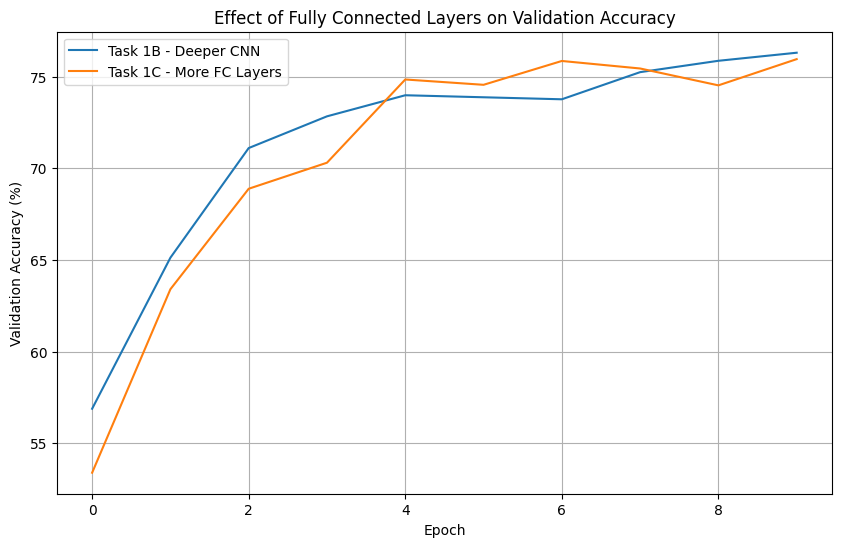

In [39]:
plt.figure(figsize=(10, 6))

plt.plot(
    test_accuracies_deep,
    label="Task 1B - Deeper CNN"
)

plt.plot(
    test_accuracies_fc,
    label="Task 1C - More FC Layers"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Effect of Fully Connected Layers on Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

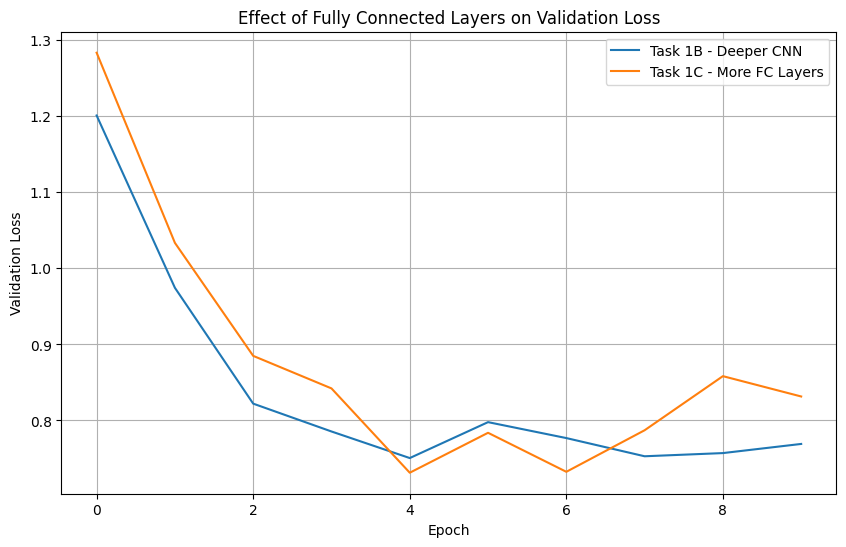

In [40]:
plt.figure(figsize=(10, 6))

plt.plot(
    test_losses_deep,
    label="Task 1B - Deeper CNN"
)

plt.plot(
    test_losses_fc,
    label="Task 1C - More FC Layers"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Effect of Fully Connected Layers on Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [41]:
print(
    "Task 1B Final Accuracy:",
    round(test_accuracies_deep[-1], 2),
    "%"
)

print(
    "Task 1C Final Accuracy:",
    round(test_accuracies_fc[-1], 2),
    "%"
)

print(
    "Task 1B Final Loss:",
    round(test_losses_deep[-1], 4)
)

print(
    "Task 1C Final Loss:",
    round(test_losses_fc[-1], 4)
)

Task 1B Final Accuracy: 76.3 %
Task 1C Final Accuracy: 75.95 %
Task 1B Final Loss: 0.7691
Task 1C Final Loss: 0.8315


## Task 1C: Effect of Fully Connected Layers and Neurons

To study the effect of the fully connected classifier, the convolutional architecture from Task 1B was retained while the fully connected layers were changed.

The Task 1B model used:

`2048 → 128 → 10`

The Task 1C model used:

`2048 → 256 → 128 → 10`

The Task 1B model achieved **76.30% test accuracy** and **0.7691 test loss**.

The Task 1C model achieved **75.95% test accuracy** and **0.8315 test loss**.

Although the modified fully connected network had greater capacity, it did not improve test accuracy. Its training accuracy reached **89.55%**, while test accuracy remained at **75.95%**, indicating increased overfitting.

**Conclusion:** Adding more fully connected layers and neurons did not improve generalization. The Task 1B architecture provided better test performance with a simpler classifier.

Therefore, Task 1B is selected as the starting architecture for further improvement.

# Improving the accuracy of the model

In [42]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Subset

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training augmentation
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

# Validation/test preprocessing
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

train_full = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True,
    transform=train_transform
)

val_full = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True,
    transform=eval_transform
)

test_final = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True,
    transform=eval_transform
)

indices = torch.randperm(50000, generator=torch.Generator().manual_seed(42))

train_indices = indices[:45000].tolist()
val_indices = indices[45000:].tolist()

train_improved = Subset(train_full, train_indices)
val_improved = Subset(val_full, val_indices)

train_loader_improved = DataLoader(
    train_improved, batch_size=128, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

val_loader_improved = DataLoader(
    val_improved, batch_size=128, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

test_loader_final = DataLoader(
    test_final, batch_size=128, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

print("Training:", len(train_improved))
print("Validation:", len(val_improved))
print("Testing:", len(test_final))

Training: 45000
Validation: 5000
Testing: 10000


In [43]:
class ImprovedCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.2),

            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model_improved = ImprovedCNN().to(device)

criterion_improved = nn.CrossEntropyLoss()

optimizer_improved = optim.Adam(
    model_improved.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print(model_improved)

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout2d(p=0

In [44]:
train_losses_imp = []
val_losses_imp = []
train_acc_imp = []
val_acc_imp = []

best_val_loss = float("inf")
best_weights = None
patience = 5
wait = 0

epochs = 30

for epoch in range(epochs):

    model_improved.train()

    train_loss_sum = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_improved:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_improved.zero_grad()

        outputs = model_improved(images)
        loss = criterion_improved(outputs, labels)

        loss.backward()
        optimizer_improved.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = 100 * train_correct / train_total

    model_improved.eval()

    val_loss_sum = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader_improved:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_improved(images)
            loss = criterion_improved(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    train_losses_imp.append(train_loss)
    val_losses_imp.append(val_loss)
    train_acc_imp.append(train_accuracy)
    val_acc_imp.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model_improved.state_dict())
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early Stopping triggered.")
        break

model_improved.load_state_dict(best_weights)

print("Training completed after", len(train_losses_imp), "epochs")

Epoch 1/30 | Train Acc: 30.85% | Val Acc: 42.12% | Train Loss: 1.8308 | Val Loss: 1.5392
Epoch 2/30 | Train Acc: 39.83% | Val Acc: 52.58% | Train Loss: 1.5940 | Val Loss: 1.2655
Epoch 3/30 | Train Acc: 43.89% | Val Acc: 59.62% | Train Loss: 1.4866 | Val Loss: 1.1736
Epoch 4/30 | Train Acc: 47.20% | Val Acc: 60.18% | Train Loss: 1.4090 | Val Loss: 1.0948
Epoch 5/30 | Train Acc: 49.37% | Val Acc: 64.08% | Train Loss: 1.3574 | Val Loss: 1.0248
Epoch 6/30 | Train Acc: 51.37% | Val Acc: 66.42% | Train Loss: 1.3124 | Val Loss: 0.9228
Epoch 7/30 | Train Acc: 52.84% | Val Acc: 68.72% | Train Loss: 1.2780 | Val Loss: 0.9078
Epoch 8/30 | Train Acc: 54.16% | Val Acc: 69.42% | Train Loss: 1.2457 | Val Loss: 0.8602
Epoch 9/30 | Train Acc: 54.85% | Val Acc: 68.92% | Train Loss: 1.2194 | Val Loss: 0.8709
Epoch 10/30 | Train Acc: 55.68% | Val Acc: 70.60% | Train Loss: 1.1973 | Val Loss: 0.8324
Epoch 11/30 | Train Acc: 56.81% | Val Acc: 71.54% | Train Loss: 1.1748 | Val Loss: 0.7912
Epoch 12/30 | Train

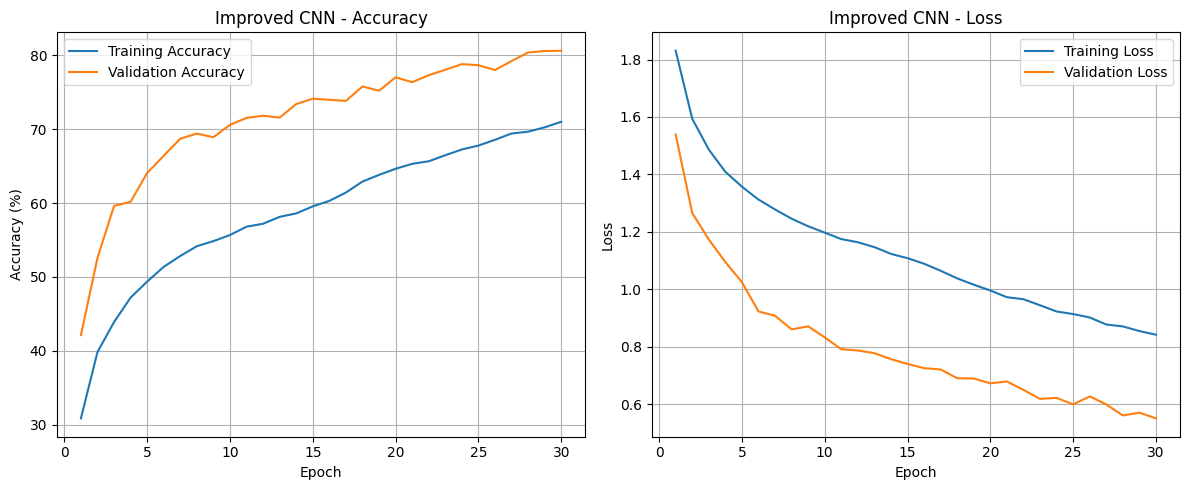

In [45]:
epoch_numbers = range(1, len(train_acc_imp) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, train_acc_imp, label="Training Accuracy")
plt.plot(epoch_numbers, val_acc_imp, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Improved CNN - Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, train_losses_imp, label="Training Loss")
plt.plot(epoch_numbers, val_losses_imp, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN - Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Task 3: Reducing Overfitting and Underfitting

### Observation Before Improvement

The deeper CNN developed in Task 1B achieved **88.16% training accuracy** and **76.30% test accuracy**, indicating a noticeable gap between training and test performance.

Task 1C showed an even larger gap, with **89.55% training accuracy** and **75.95% test accuracy**. This suggested that increasing model complexity was also increasing overfitting.

### Techniques Applied

To improve generalization, the following techniques were implemented:

- **Data Augmentation:** Random cropping, horizontal flipping, and rotation.
- **Dropout:** Randomly disabling selected neurons and feature maps during training.
- **Weight Decay:** Penalizing excessively large weights.
- **Batch Normalization:** Improving training stability.
- **Early Stopping:** Monitoring validation loss to stop training when performance no longer improves.

### Analysis of Improved Model Graphs

The improved model's training accuracy increased from **30.85% to 71.01%**, while validation accuracy increased from **42.12% to 80.64%**.

Training loss decreased from **1.8308 to 0.8418**, while validation loss decreased from **1.5392 to 0.5505**.

Both training and validation curves demonstrate consistent learning without a sustained deterioration in validation performance.

Validation accuracy remained higher than training accuracy because augmentation and Dropout were applied during training, making the training conditions more challenging. During validation, these training-time modifications were not applied.

Although Early Stopping was implemented, it was not triggered because validation loss continued improving during the 30-epoch training period.

### Conclusion

The improved CNN demonstrated better generalization than the earlier models. The validation accuracy increased and validation loss decreased, without clear evidence of severe overfitting.

The combination of data augmentation, Dropout, Batch Normalization, and weight decay helped reduce the generalization problem observed in the earlier architectures.

Therefore, the model's overfitting tendency was reduced, although it cannot be guaranteed that overfitting has been completely eliminated.

In [46]:
model_improved.eval()

correct = 0
total = 0
loss_sum = 0

with torch.no_grad():
    for images, labels in test_loader_final:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_improved(images)
        loss = criterion_improved(outputs, labels)

        loss_sum += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

improved_test_accuracy = 100 * correct / total
improved_test_loss = loss_sum / total

print("Improved Test Accuracy:", round(improved_test_accuracy, 2), "%")
print("Improved Test Loss:", round(improved_test_loss, 4))

print("Previous Baseline Accuracy: 67.84%")
print("Previous Task 1B Accuracy: 76.30%")

Improved Test Accuracy: 80.31 %
Improved Test Loss: 0.5757
Previous Baseline Accuracy: 67.84%
Previous Task 1B Accuracy: 76.30%


## Task 2: Improving CNN Accuracy

To improve the classification performance of the CNN, the deeper architecture from Task 1B was modified using several techniques:

- **Data Augmentation:** Random cropping, horizontal flipping, and rotation were applied to increase training-image variability.
- **Batch Normalization:** Added after convolutional layers to improve training stability.
- **Dropout:** Applied to convolutional feature maps and the fully connected layer to reduce dependence on individual features.
- **Weight Decay:** Used to penalize excessively large weights and improve generalization.
- **Early Stopping:** Implemented to monitor validation loss and restore the best model weights when necessary.

### Results

| Model | Test Accuracy | Test Loss |
|---|---:|---:|
| Baseline CNN | 67.84% | 0.9194 |
| Deeper CNN (Task 1B) | 76.30% | 0.7691 |
| Improved CNN | **80.31%** | **0.5757** |

The improved CNN achieved the highest test accuracy and lowest test loss among the tested models.

Compared with the original baseline, test accuracy increased by **12.47 percentage points**.

### Conclusion

The combination of a deeper convolutional architecture, data augmentation, Batch Normalization, Dropout, and weight decay improved classification performance on CIFAR-10.

The improved model achieved **80.31% test accuracy**, demonstrating better generalization than the original CNN in these experiments.

In [47]:
from google.colab import drive
drive.mount("/content/drive")

save_path = "/content/drive/MyDrive/Tutorial5_Improved_CNN.pth"

torch.save({
    "model_state_dict": model_improved.state_dict(),
    "train_losses": train_losses_imp,
    "val_losses": val_losses_imp,
    "train_accuracies": train_acc_imp,
    "val_accuracies": val_acc_imp,
    "test_accuracy": improved_test_accuracy,
    "test_loss": improved_test_loss
}, save_path)

print("Saved successfully:", save_path)

Mounted at /content/drive
Saved successfully: /content/drive/MyDrive/Tutorial5_Improved_CNN.pth
